# Trois campagnes ciblées et gains attendus (SIMULATION)

Equipe 5, module Webmarketing et CRM (TDIA3). Suite des notebooks 02 (RFM) et 03 (churn).

> **Tout ce qui est chiffré ici est une simulation.** Les données ne contiennent ni adresse e-mail, ni résultat de campagne, ni marge, ni coût. **Aucun message n'a été envoyé et aucun effet réel n'a été mesuré.** Le taux de réactivation, la marge, les coûts et les taux d'usage des offres sont des **hypothèses** choisies avant de calculer, à remplacer par des valeurs réelles. Les chiffres issus des données décrivent la situation « sans campagne » (effectifs, taux de départ, paniers historiques). **Le taux de départ est observé rétrospectivement** sur la période du 2011-09-01 au 2011-11-30 : il n'était pas disponible à la date fictive de lancement. **Les données ne permettent pas de savoir si les clients ont reçu d'autres campagnes** (e-mails, promotions, appels) pendant cette période.

**Données.** Online Retail II (Chen, D., 2012, https://doi.org/10.24432/C5CG6D, CC BY 4.0). Ventes brutes, retours non déduits. Monnaie : GBP.

**Date de campagne simulée : 2011-09-01.** On suppose qu'une campagne aurait été lancée ce jour-là, avec les seules informations connues à cette date, puis on regarde la période du 2011-09-01 au 2011-11-30.

## 1. Une seule version des segments

Les campagnes utilisent **uniquement les segments du notebook 03** : standardisation et K-means (k = 4, graine 42) ajustés sur les instantanés d'entraînement et de validation (2010-06-01 à 2011-06-01), puis appliqués aux clients du 2011-09-01 sans réajustement. Les segments du notebook 02 portent les mêmes noms mais ont des frontières différentes (les « Récents à développer » passent de 753 à 367 clients) ; ils ne sont pas utilisés ici. La différence est expliquée dans le notebook 03 et dans `docs/etape3_churn.md`.

Le **risque** est le score de la régression logistique du notebook 03 (modèle retenu). Il ne sert qu'à **classer** les clients : les probabilités ne sont pas calibrées (section 3).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import campaigns as cp
import churn as ch
import data_prep

CAMPAIGN_DATE = pd.Timestamp("2011-09-01")
SEGMENT_VERSION = "notebook 03 : Segmenter ajusté sur 2010-06-01 à 2011-06-01, appliqué au 2011-09-01"
OUT_TARGETS = ROOT / "data" / "processed" / "campaign_targets_2011-09-01.parquet"
OUT_TARGETS_SUMMARY = ROOT / "reports" / "campaigns_targets.csv"
OUT_ASSUMPTIONS = ROOT / "reports" / "campaigns_assumptions.csv"
OUT_SIMULATION = ROOT / "reports" / "campaigns_simulation.csv"
OUT_BE_SENS = ROOT / "reports" / "campaigns_breakeven_sensitivity.csv"
OUT_FIGS = ROOT / "reports" / "figures"; OUT_FIGS.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 220, "display.max_columns", 40)
print("Segments utilisés :", SEGMENT_VERSION)

Segments utilisés : notebook 03 : Segmenter ajusté sur 2010-06-01 à 2011-06-01, appliqué au 2011-09-01


## 2. Données et contrôles

In [2]:
assert data_prep.verify() == 0, "Les données ne correspondent pas au rapport : relancer python src/data_prep.py"
purchases = pd.read_parquet(ROOT / "data" / "processed" / "purchases.parquet")
returns = pd.read_parquet(ROOT / "data" / "processed" / "returns.parquet")
preds = pd.read_parquet(ROOT / "data" / "processed" / "churn_test_predictions.parquet")
assert preds.customer_id.is_unique and (preds.snapshot_date == CAMPAIGN_DATE).all()

feats = ch.build_features(purchases, returns, CAMPAIGN_DATE)           # uniquement des lignes < 2011-09-01
assert set(feats.index) == set(preds.customer_id), "clients du test différents de ceux des prédictions"
df = preds.merge(feats[["avg_basket_gbp", "frequency", "monetary_brut_gbp"]], left_on="customer_id", right_index=True, how="left")
df = df.sort_values("customer_id").reset_index(drop=True)
assert df[["avg_basket_gbp", "proba_logistique", "segment"]].notna().all().all()

ref = pd.read_csv(ROOT / "reports" / "churn_by_segment.csv", encoding="utf-8").set_index("segment")["clients"]
assert df.segment.value_counts().reindex(ref.index).equals(ref.astype(df.segment.value_counts().dtype)), "segments différents du notebook 03"
print(f"\n{len(df):,} clients actifs au {CAMPAIGN_DATE:%Y-%m-%d} ; effectifs par segment identiques à reports/churn_by_segment.csv")
print("Aucune colonne d'adresse ou de contact dans les données :", [c for c in df.columns if "mail" in c.lower()] == [])
df.groupby("segment").agg(clients=("customer_id", "size"), panier_median_gbp=("avg_basket_gbp", "median"),
                          frequence_mediane=("frequency", "median")).reindex(["Champions", "Réguliers à risque", "Récents à développer", "Endormis"]).round(1)

OK    zip = valeur epinglee  (reference : 572E36277C2390FBFDE10664750731E0A86F55E33470D91919085F0408E67BFB)
OK    zip = rapport  (reference : 572E36277C2390FBFDE10664750731E0A86F55E33470D91919085F0408E67BFB)
OK    zip = manifeste  (reference : 572E36277C2390FBFDE10664750731E0A86F55E33470D91919085F0408E67BFB)
OK    xlsx = contenu du zip  (reference : BCBE73B35F5B7BABF197FB0CB983A11F5D9FF929078D4AA53D171B1F2DF2E980)
OK    xlsx = rapport  (reference : BCBE73B35F5B7BABF197FB0CB983A11F5D9FF929078D4AA53D171B1F2DF2E980)
OK    xlsx = manifeste  (reference : BCBE73B35F5B7BABF197FB0CB983A11F5D9FF929078D4AA53D171B1F2DF2E980)
OK    raw.parquet = manifeste  (reference : 121686E90C9CEEBDA6F38B802C0D2118887053AB2698ABD5BAC97F68D44F00CE)
OK    schema du cache a jour  (reference : 2)
OK    raw.parquet : lignes = rapport  (reference : 1067371)
OK    purchases.parquet : lignes = rapport  (reference : 788127)
OK    returns.parquet : lignes = rapport  (reference : 17641)
OK    raw.parquet : SHA-256 = rappo


5,224 clients actifs au 2011-09-01 ; effectifs par segment identiques à reports/churn_by_segment.csv
Aucune colonne d'adresse ou de contact dans les données : True


,clients,panier_median_gbp,frequence_mediane
segment,,,
Champions,899,364.4,13.0
Réguliers à risque,1833,309.4,4.0
Récents à développer,367,258.4,2.0
Endormis,2125,207.0,1.0


## 3. Classer par risque plutôt que lire les probabilités

Le notebook 03 a montré que la probabilité moyenne prédite dépasse le churn réel de 5 à 14 points selon les segments. On vérifie ici si le **classement** reste fiable : les clients sont regroupés en dix groupes de taille égale, du moins au plus à risque, et on compare la probabilité moyenne prédite au taux de départ observé.

,clients,proba_moyenne,churn_observe,écart
decile_risque,,,,
1,523,0.143,0.067,0.076
2,522,0.354,0.243,0.110
3,522,0.508,0.397,0.112
4,523,0.622,0.514,0.108
5,522,0.709,0.571,0.138
6,522,0.769,0.669,0.100
7,523,0.812,0.755,0.057
8,522,0.846,0.766,0.080
9,522,0.869,0.849,0.020


Corrélation de rang entre décile de risque et churn observé : 1.000
Écart moyen probabilité - churn observé : +0.081


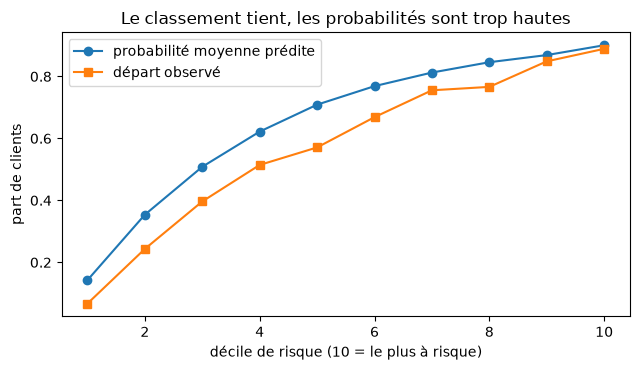

In [3]:
df["decile_risque"] = pd.qcut(df.proba_logistique.rank(method="first"), 10, labels=range(1, 11)).astype(int)
cal = df.groupby("decile_risque").agg(clients=("customer_id", "size"), proba_moyenne=("proba_logistique", "mean"),
                                       churn_observe=("churn_reel", "mean"))
cal["écart"] = cal.proba_moyenne - cal.churn_observe
display(cal.round(3))
print(f"Corrélation de rang entre décile de risque et churn observé : {cal.index.to_series().corr(cal.churn_observe, method='spearman'):.3f}")
print(f"Écart moyen probabilité - churn observé : {df.proba_logistique.mean() - df.churn_reel.mean():+.3f}")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(cal.index, cal.proba_moyenne, "o-", label="probabilité moyenne prédite")
ax.plot(cal.index, cal.churn_observe, "s-", label="départ observé")
ax.set_xlabel("décile de risque (10 = le plus à risque)"); ax.set_ylabel("part de clients"); ax.legend(); ax.set_title("Le classement tient, les probabilités sont trop hautes")
plt.tight_layout(); fig.savefig(OUT_FIGS / "campagnes_calibration.png", dpi=120); plt.show()

**Lecture.**

* **Le classement est fiable.** Le taux de départ observé augmente à chaque décile, de 6,7 % (décile 1) à 88,9 % (décile 10). On peut donc s'en servir pour choisir qui cibler.
* **Les probabilités ne le sont pas.** La probabilité moyenne prédite (65,3 %) dépasse le départ observé (57,2 %) de 8,1 points. L'écart atteint 13,8 points au cinquième décile et tombe à 1 ou 2 points dans les deux derniers.
* **Conséquence pour la suite.** Les clients sont choisis par leur **rang** dans le segment. Le taux de départ de chaque population ciblée est **mesuré**, jamais lu sur la probabilité.

## 4. Les trois campagnes (définies avant de regarder les résultats chiffrés)

La population de chaque campagne est définie par **un segment et une part des clients les plus à risque de ce segment**, classés par score. Ces règles ne regardent jamais le résultat observé.

| | Population ciblée | Action | Offre |
|---|---|---|---|
| **C1. Champions à risque** | les 25 % de Champions les plus à risque | **Fidéliser sans brader** : contact personnalisé, accès anticipé aux nouveautés | aucune remise |
| **C2. Réguliers à risque** | les 50 % de Réguliers à risque les plus à risque | **Relancer avant la dormance** : e-mail personnalisé qui rappelle les catégories habituelles | remise de 10 %, durée limitée |
| **C3. Récents à développer** | tous les Récents à développer | **Encourager le prochain achat** : séquence de bienvenue et recommandations de produits complémentaires | incitation de 5 % (par exemple livraison offerte) |

Les **Endormis** ne sont pas ciblés dans cette version : leur taux de départ est le plus haut, donc le gain espéré par client contacté est le plus faible. Ce n'est pas une preuve : l'effet d'une campagne sur eux n'est pas mesuré. Les **Champions les moins à risque** ne reçoivent rien : pas de remise à des clients qui achèteraient de toute façon.

In [4]:
CAMPAIGNS = [
    {"id": "C1", "nom": "Champions à risque : fidéliser sans brader", "segment": "Champions", "fraction": 0.25, "remise": 0.00},
    {"id": "C2", "nom": "Réguliers à risque : relancer avant la dormance", "segment": "Réguliers à risque", "fraction": 0.50, "remise": 0.10},
    {"id": "C3", "nom": "Récents à développer : encourager le prochain achat", "segment": "Récents à développer", "fraction": 1.00, "remise": 0.05},
]

df["rang_risque_segment"] = cp.risk_rank_in_segment(df)
rows, target_frames = [], []
for c in CAMPAIGNS:
    idx = cp.select_targets(df, c["segment"], c["fraction"])
    g = df.loc[idx]
    rows.append({"campagne": c["id"], "segment": c["segment"], "part_du_segment_ciblée": c["fraction"],
                 "clients_ciblés": len(g), "clients_du_segment": int((df.segment == c["segment"]).sum()),
                 "départ_observé_sans_campagne": g.churn_reel.mean(),
                 "probabilité_moyenne_prédite (non calibrée)": g.proba_logistique.mean(),
                 "panier_médian_historique_gbp": g.avg_basket_gbp.median(),
                 "factures_médianes_avant_T": g.frequency.median()})
    target_frames.append(g.assign(campagne=c["id"])[["customer_id", "campagne", "segment", "rang_risque_segment", "proba_logistique"]])
targets = pd.DataFrame(rows).set_index("campagne")
display(targets.round(3))
targets.round(4).reset_index().to_csv(OUT_TARGETS_SUMMARY, index=False, encoding="utf-8")
assert pd.concat(target_frames).customer_id.is_unique, "un client est dans deux campagnes"

,segment,part_du_segment_ciblée,clients_ciblés,clients_du_segment,départ_observé_sans_campagne,probabilité_moyenne_prédite (non calibrée),panier_médian_historique_gbp,factures_médianes_avant_T
campagne,,,,,,,,
C1,Champions,0.25,225,899,0.347,0.431,359.705,9.0
C2,Réguliers à risque,0.50,917,1833,0.664,0.767,303.450,3.0
C3,Récents à développer,1.00,367,367,0.431,0.573,258.380,2.0


**Lecture.**

* Effectifs : 225 clients sur 899 Champions (C1), 917 sur 1 833 Réguliers à risque (C2), 367 Récents à développer (C3). Au total 1 509 clients, soit 28,9 % des 5 224 clients actifs. Les trois populations sont disjointes (contrôlé dans la cellule).
* Le classement par risque trie bien après coup : le départ observé est de 34,7 % chez les 25 % de Champions les plus à risque, contre 16,5 % pour l'ensemble des Champions. Il est de 66,4 % chez la moitié la plus à risque des Réguliers, contre 54,3 % pour le segment entier.
* Les probabilités moyennes prédites de ces populations (43,1 %, 76,7 % et 57,3 %) surestiment le départ mesuré (34,7 %, 66,4 % et 43,1 %).
* **Le taux de départ p0 est observé rétrospectivement.** Il vient de la période du 2011-09-01 au 2011-11-30. Il **n'était donc pas disponible à la date fictive de lancement**, le 2011-09-01. Il sert ici à décrire la situation « sans campagne » de la simulation. Pour une vraie campagne, il faudrait l'estimer à partir d'une période déjà terminée, avec une incertitude plus grande : le taux de départ des instantanés varie de 41,7 % à 67,1 %.
* **« Sans campagne » veut dire « sans campagne connue ».** Les données ne contiennent rien sur les messages, promotions ou appels reçus par les clients. On ne peut pas savoir si ces clients ont reçu d'autres campagnes pendant la période. Le taux p0 peut donc déjà inclure l'effet d'actions marketing inconnues, et l'effet supposé de nos campagnes pourrait s'ajouter à elles ou se recouvrir avec elles.* Les parts ciblées (25 %, 50 %, 100 %) ont été fixées à l'avance. Elles n'ont pas été optimisées.

## 5. Hypothèses et formule du gain net (SIMULATION)

**Formule** (pour une campagne et un scénario) :

* `clients qui partiraient` = N × p0, avec N = clients ciblés et **p0 = part des clients ciblés qui n'achètent pas dans les 90 jours sans campagne**. p0 est **observé rétrospectivement** sur la période du 2011-09-01 au 2011-11-30 : il n'était pas connu au lancement fictif. Il n'est pas lu sur les probabilités. Les données ne disent pas si ces clients ont reçu d'autres campagnes : « sans campagne » signifie « sans campagne connue ».
* `réactivation additionnelle` = N × p0 × r, avec **r = part des clients qui seraient partis et que la campagne fait racheter** (hypothèse).
* `marge gagnée` = réactivation × commandes × panier × facteur de panier × (m − d), avec m la marge, d la remise. Une seule commande par client réactivé.
* `coût de cannibalisation` = N × (1 − p0) × s × panier × d : remises données à des clients qui auraient acheté de toute façon (s = part d'entre eux qui utilise l'offre).
* `gain net` = marge gagnée − cannibalisation − N × coût par contact − coût fixe.
* `seuil de rentabilité` : valeur de r pour laquelle le gain net est nul.

Le **panier** est le panier médian historique des clients ciblés (ventes brutes avant le 2011-09-01, retours non déduits). Il est issu des données ; **tout le reste (r, m, coûts, s) est une hypothèse sans source dans les données.** Le scénario « prudent » combine toutes les hypothèses défavorables, il est donc plus sévère que chaque hypothèse prise seule.

In [5]:
SCEN = ["prudent", "central", "optimiste"]
ASSUMPTIONS = {
    #                         prudent / central / optimiste
    "reactivation_r": {"C1": (0.05, 0.10, 0.15), "C2": (0.03, 0.06, 0.10), "C3": (0.05, 0.08, 0.12)},
    "marge_m":        {"C1": (0.25, 0.30, 0.35), "C2": (0.25, 0.30, 0.35), "C3": (0.25, 0.30, 0.35)},
    "cout_par_contact_gbp": {"C1": (8.00, 5.00, 3.00), "C2": (0.10, 0.05, 0.03), "C3": (0.10, 0.05, 0.03)},
    "cout_fixe_gbp":  {"C1": (300, 200, 150), "C2": (300, 200, 150), "C3": (300, 200, 150)},
    "usage_offre_s":  {"C1": (0.0, 0.0, 0.0), "C2": (0.20, 0.15, 0.10), "C3": (0.15, 0.10, 0.05)},
    "facteur_panier": {"C1": (0.8, 1.0, 1.0), "C2": (0.8, 1.0, 1.0), "C3": (0.8, 1.0, 1.0)},
}
ORDERS = 1.0       # commandes par client réactivé sur la fenêtre de 90 jours (hypothèse prudente)

rows = []
for c in CAMPAIGNS:
    for k, s in enumerate(SCEN):
        rows.append({"type": "SIMULATION", "campagne": c["id"], "scénario": s, "remise_d": c["remise"], "commandes_par_client_réactivé": ORDERS,
                     **{name: vals[c["id"]][k] for name, vals in ASSUMPTIONS.items()}})
assumptions = pd.DataFrame(rows)
display(assumptions)
assumptions.to_csv(OUT_ASSUMPTIONS, index=False, encoding="utf-8")

,type,campagne,scénario,remise_d,commandes_par_client_réactivé,reactivation_r,marge_m,cout_par_contact_gbp,cout_fixe_gbp,usage_offre_s,facteur_panier
0,SIMULATION,C1,prudent,0.00,1.0,0.05,0.25,8.00,300,0.00,0.8
1,SIMULATION,C1,central,0.00,1.0,0.10,0.30,5.00,200,0.00,1.0
2,SIMULATION,C1,optimiste,0.00,1.0,0.15,0.35,3.00,150,0.00,1.0
3,SIMULATION,C2,prudent,0.10,1.0,0.03,0.25,0.10,300,0.20,0.8
4,SIMULATION,C2,central,0.10,1.0,0.06,0.30,0.05,200,0.15,1.0
5,SIMULATION,C2,optimiste,0.10,1.0,0.10,0.35,0.03,150,0.10,1.0
6,SIMULATION,C3,prudent,0.05,1.0,0.05,0.25,0.10,300,0.15,0.8
7,SIMULATION,C3,central,0.05,1.0,0.08,0.30,0.05,200,0.10,1.0
8,SIMULATION,C3,optimiste,0.05,1.0,0.12,0.35,0.03,150,0.05,1.0


## 6. Résultats de la simulation

**SIMULATION : ces montants ne sont pas des résultats mesurés.** Ils découlent des hypothèses de la section 5.

In [6]:
def params(c_id, scenario):
    c = next(x for x in CAMPAIGNS if x["id"] == c_id)
    k = SCEN.index(scenario)
    t = targets.loc[c_id]
    a = {name: vals[c_id][k] for name, vals in ASSUMPTIONS.items()}
    return dict(n_targeted=int(t["clients_ciblés"]), base_churn=t["départ_observé_sans_campagne"],
                basket_gbp=t["panier_médian_historique_gbp"], reactivation=a["reactivation_r"], margin=a["marge_m"],
                discount=c["remise"], redemption=a["usage_offre_s"], contact_cost=a["cout_par_contact_gbp"],
                fixed_cost=a["cout_fixe_gbp"], orders=ORDERS, basket_factor=a["facteur_panier"])

def run(c_id, scenario, **override):
    # `override` remplace certains paramètres (par exemple base_churn ou reactivation)
    return cp.simulate(**{**params(c_id, scenario), **override})
sim = pd.DataFrame([{"type": "SIMULATION", "campagne": c["id"], "scénario": s, **run(c["id"], s)} for c in CAMPAIGNS for s in SCEN])
sim["gain_net_par_client_ciblé_gbp"] = sim.gain_net_gbp / sim.clients_cibles
show = sim.pivot(index="campagne", columns="scénario", values="gain_net_gbp")[SCEN]
show.loc["Total (C1+C2+C3)"] = show.sum()
print("SIMULATION - gain net (GBP) par campagne et par scénario")
display(show.round(0))
print("SIMULATION - détail du scénario central")
display(sim[sim["scénario"] == "central"].set_index("campagne")[[
    "clients_cibles", "clients_qui_partiraient", "clients_reactives", "ventes_brutes_additionnelles_gbp", "marge_gagnee_gbp",
    "cout_cannibalisation_gbp", "cout_contacts_gbp", "cout_fixe_gbp", "gain_net_gbp", "seuil_rentabilite_reactivation"]].round(2))
sim.round(4).to_csv(OUT_SIMULATION, index=False, encoding="utf-8")

SIMULATION - gain net (GBP) par campagne et par scénario


scénario,prudent,central,optimiste
campagne,,,
C1,-1819.0,-483.0,648.0
C2,-1596.0,570.0,3508.0
C3,-415.0,328.0,1174.0
Total (C1+C2+C3),-3830.0,415.0,5330.0


SIMULATION - détail du scénario central


,clients_cibles,clients_qui_partiraient,clients_reactives,ventes_brutes_additionnelles_gbp,marge_gagnee_gbp,cout_cannibalisation_gbp,cout_contacts_gbp,cout_fixe_gbp,gain_net_gbp,seuil_rentabilite_reactivation
campagne,,,,,,,,,,
C1,225,78.0,7.80,2805.70,841.71,0.00,1125.00,200,-483.29,0.16
C2,917,609.0,36.54,11088.06,2217.61,1401.94,45.85,200,569.82,0.04
C3,367,158.0,12.64,3265.92,816.48,270.01,18.35,200,328.12,0.05


**SIMULATION. Gain net en GBP.**

| | Prudent | Central | Optimiste |
|---|---:|---:|---:|
| C1. Champions à risque (225 clients) | -1 819 | -483 | +648 |
| C2. Réguliers à risque (917 clients) | -1 596 | +570 | +3 508 |
| C3. Récents à développer (367 clients) | -415 | +328 | +1 174 |
| **Total** | **-3 830** | **+415** | **+5 330** |

**Lecture.**

* **Le signe du résultat dépend des hypothèses.** Le total va de -3 830 à +5 330 GBP selon le scénario. Le scénario central est à peine positif : +415 GBP pour 1 509 clients contactés, soit environ 0,28 GBP par client.
* **C1 (Champions, sans remise) est la seule campagne négative au central.** Le coût des contacts (5 GBP × 225 = 1 125 GBP) dépasse la marge gagnée (842 GBP). Pour équilibrer à r = 10 %, en couvrant les 200 GBP de coût fixe, le coût par contact devrait être d'au plus 2,85 GBP.
* **C2 a le meilleur gain central (+570 GBP) mais la remise coûte cher.** La cannibalisation (remises données à des clients qui auraient acheté de toute façon) représente 1 402 GBP, soit 63 % de la marge gagnée (2 218 GBP).
* **C3 est positive au central (+328 GBP)** : 12,6 clients réactivés sur 158 qui partiraient, pour 367 contacts.
* Le détail des composantes (clients qui partiraient, clients réactivés, ventes additionnelles, marge, coûts) est dans le tableau du scénario central et dans `reports/campaigns_simulation.csv`.

### Ce qui se passerait avec les probabilités brutes (à ne pas faire)

Si l'on prenait la probabilité moyenne prédite comme taux de départ p0 au lieu du taux mesuré, le gain central serait surévalué :

In [7]:
rows = []
for c in CAMPAIGNS:
    p_raw = targets.loc[c["id"], "probabilité_moyenne_prédite (non calibrée)"]
    g_ok = run(c["id"], "central")["gain_net_gbp"]
    g_raw = run(c["id"], "central", base_churn=p_raw)["gain_net_gbp"]
    rows.append({"campagne": c["id"], "p0 mesuré": targets.loc[c["id"], "départ_observé_sans_campagne"], "p0 = probabilité brute": p_raw,
                 "gain central (p0 mesuré), GBP": g_ok, "gain central (probabilité brute), GBP": g_raw, "écart, GBP": g_raw - g_ok})
bias = pd.DataFrame(rows).set_index("campagne")
print("SIMULATION - effet d'une probabilité non calibrée sur le gain central")
display(bias.round(2))

SIMULATION - effet d'une probabilité non calibrée sur le gain central


,p0 mesuré,p0 = probabilité brute,"gain central (p0 mesuré), GBP","gain central (probabilité brute), GBP","écart, GBP"
campagne,,,,,
C1,0.35,0.43,-483.29,-279.73,203.56
C2,0.66,0.77,569.82,1343.15,773.32
C3,0.43,0.57,328.12,665.89,337.77


**Lecture.** Utiliser la probabilité brute plutôt que le taux mesuré gonfle le gain central de 773 GBP pour C2 (de +570 à +1 343 GBP, plus du double), de 338 GBP pour C3 (de +328 à +666 GBP) et de 204 GBP pour C1 (la perte passe de -483 à -280 GBP). Le biais est toujours optimiste : la probabilité surestime le départ, donc le nombre de clients à récupérer. La simulation part pour cette raison de taux mesurés.

## 7. Sensibilité : de quelle réactivation a-t-on besoin ?

Le taux de réactivation r est l'hypothèse la plus incertaine. Le graphique montre le gain net central en fonction de r, et le premier tableau le **seuil de rentabilité** (valeur de r à partir de laquelle le gain net est positif) dans chaque scénario.

**Ce seuil n'est pas une propriété des données.** Il dépend de la marge, des coûts, de l'usage des offres, du panier et du taux de départ p0, c'est-à-dire des hypothèses de la section 5 et d'un p0 observé après coup. Le second tableau le recalcule en changeant une hypothèse à la fois.

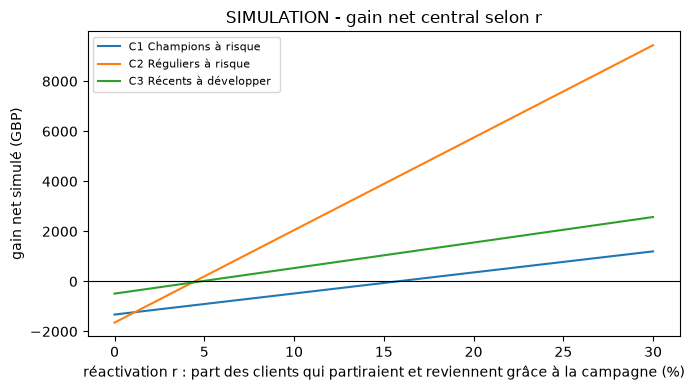

SIMULATION - seuil de rentabilité de r (part des clients qui partiraient et qu'il faut récupérer) et r supposé


seuil de rentabilité                   r supposé                  
scénario              prudent central optimiste   prudent central optimiste
campagne                                                                   
C1                      0.374   0.157     0.084      0.05    0.10      0.15
C2                      0.102   0.045     0.024      0.03    0.06      0.10
C3                      0.114   0.048     0.024      0.05    0.08      0.12

SIMULATION - seuil de rentabilité de r selon l'hypothèse modifiée (une à la fois)


,C1,C2,C3
"variation (une seule à la fois, scénario central)",,,
référence (scénario central),0.157,0.045,0.048
marge 25 % au lieu de 30 %,0.189,0.059,0.060
marge 35 % au lieu de 30 %,0.135,0.036,0.040
coût par contact × 2,0.291,0.046,0.050
coût par contact ÷ 2,0.091,0.044,0.047
usage de l'offre × 2 (clients qui auraient acheté),0.157,0.083,0.074
panier historique − 20 %,0.197,0.046,0.053
départ sans campagne p0 − 10 points,0.221,0.066,0.068
départ sans campagne p0 + 10 points,0.122,0.029,0.035


In [8]:
rs = np.linspace(0, 0.30, 61)
fig, ax = plt.subplots(figsize=(7, 4))
for c in CAMPAIGNS:
    ax.plot(rs * 100, [run(c["id"], "central", reactivation=r)["gain_net_gbp"] for r in rs], label=c["id"] + " " + c["nom"].split(":")[0])
ax.axhline(0, color="k", lw=.8); ax.set_xlabel("réactivation r : part des clients qui partiraient et reviennent grâce à la campagne (%)")
ax.set_ylabel("gain net simulé (GBP)"); ax.set_title("SIMULATION - gain net central selon r"); ax.legend(fontsize=8)
plt.tight_layout(); fig.savefig(OUT_FIGS / "campagnes_sensibilite_r.png", dpi=120); plt.show()

be = sim.pivot(index="campagne", columns="scénario", values="seuil_rentabilite_reactivation")[SCEN]
r_assumed = assumptions.pivot(index="campagne", columns="scénario", values="reactivation_r")[SCEN]
print("SIMULATION - seuil de rentabilité de r (part des clients qui partiraient et qu'il faut récupérer) et r supposé")
display(pd.concat({"seuil de rentabilité": be, "r supposé": r_assumed}, axis=1).round(3))

VARIATIONS = {
    "référence (scénario central)": lambda kw: {},
    "marge 25 % au lieu de 30 %": lambda kw: {"margin": 0.25},
    "marge 35 % au lieu de 30 %": lambda kw: {"margin": 0.35},
    "coût par contact × 2": lambda kw: {"contact_cost": 2 * kw["contact_cost"]},
    "coût par contact ÷ 2": lambda kw: {"contact_cost": kw["contact_cost"] / 2},
    "usage de l'offre × 2 (clients qui auraient acheté)": lambda kw: {"redemption": min(1.0, 2 * kw["redemption"])},
    "panier historique − 20 %": lambda kw: {"basket_gbp": 0.8 * kw["basket_gbp"]},
    "départ sans campagne p0 − 10 points": lambda kw: {"base_churn": kw["base_churn"] - 0.10},
    "départ sans campagne p0 + 10 points": lambda kw: {"base_churn": kw["base_churn"] + 0.10},
}
rows = []
for name, change in VARIATIONS.items():
    row = {"variation (une seule à la fois, scénario central)": name}
    for c in CAMPAIGNS:
        kw = params(c["id"], "central")
        row[c["id"]] = cp.simulate(**{**kw, **change(kw)})["seuil_rentabilite_reactivation"]
    rows.append(row)
be_sens = pd.DataFrame(rows).set_index("variation (une seule à la fois, scénario central)")
print("SIMULATION - seuil de rentabilité de r selon l'hypothèse modifiée (une à la fois)")
display(be_sens.round(3))
be_sens.round(4).reset_index().to_csv(OUT_BE_SENS, index=False, encoding="utf-8")

**Lecture.**

* **Sous les hypothèses de la section 5**, le seuil de rentabilité de r au scénario central est de **15,7 % (C1)**, **4,5 % (C2)** et **4,8 % (C3)**. En prudent : 37,4 %, 10,2 % et 11,4 %. En optimiste : 8,4 %, 2,4 % et 2,4 %.
* **Ces seuils dépendent des hypothèses, et d'un p0 observé après coup.** Le second tableau change une hypothèse à la fois. Le seuil de C1 passe de 15,7 % à 29,1 % si le coût par contact double, et à 9,1 % s'il est divisé par deux. Celui de C2 passe de 4,5 % à 8,3 % si l'usage de l'offre par les clients qui auraient acheté double. Une erreur de 10 points sur p0 déplace le seuil de C2 entre 2,9 % et 6,6 %, et celui de C1 entre 12,2 % et 22,1 %.
* Ils donnent un ordre de grandeur de l'effort nécessaire pour un jeu d'hypothèses donné. Ils ne sont pas plus fiables que ces hypothèses, et aucune donnée n'éclaire r.

## 8. Peut-on mesurer l'effet réel ? Taille de test nécessaire

Aucun gain réel n'a été mesuré. Pour en mesurer un, il faudrait un **groupe témoin** : une moitié des clients ciblés, tirée au sort, ne reçoit rien. On calcule l'écart minimal de taux de départ qu'un tel test détecterait (risque 5 %, puissance 80 %, groupes égaux) et on le compare à l'écart supposé au scénario central (p0 × r, en points de pourcentage).

In [9]:
rows = []
for c in CAMPAIGNS:
    t = targets.loc[c["id"]]
    n_group = int(t["clients_ciblés"]) // 2
    p0 = t["départ_observé_sans_campagne"]
    mde = cp.minimum_detectable_effect(p0, n_group)
    expected = p0 * ASSUMPTIONS["reactivation_r"][c["id"]][1]
    rows.append({"campagne": c["id"], "clients par groupe": n_group, "écart minimal détectable (pts)": 100 * mde,
                 "écart supposé central (pts)": 100 * expected, "détectable ?": "oui" if expected >= mde else "non",
                 "clients par groupe nécessaires pour détecter l'écart supposé": cp.required_n_per_group(p0, expected)})
mde_table = pd.DataFrame(rows).set_index("campagne")
display(mde_table.round(1))

,clients par groupe,écart minimal détectable (pts),écart supposé central (pts),détectable ?,clients par groupe nécessaires pour détecter l'écart supposé
campagne,,,,,
C1,112,17.8,3.5,non,2959
C2,458,8.7,4.0,non,2206
C3,183,14.5,3.4,non,3245


**Lecture.**

* Avec une moitié de clients témoins, un test détecterait un écart d'au moins 17,8 points (C1), 8,7 points (C2) et 14,5 points (C3) de taux de départ. L'écart supposé au scénario central est de 3,5, 4,0 et 3,4 points.
* **Aucune des trois campagnes ne permettrait de conclure avec ces effectifs.** Pour détecter l'écart supposé, il faudrait environ 2 959 (C1), 2 206 (C2) et 3 245 (C3) clients par groupe, soit, pour deux groupes, 5 918 (C1), 4 412 (C2) et 6 490 (C3) clients, alors que chaque campagne n'en cible que 225, 917 et 367. Pour C1 et C3, un seul groupe dépasse même la moitié de la base entière de clients actifs (2 612).
* Un test réel devrait donc s'étendre sur plusieurs vagues ou viser des effets plus grands. Sans groupe témoin, aucun gain ne peut être attribué à une campagne : un client qui rachète l'aurait peut-être fait seul.

## Limites et lecture prudente

* **Simulation, pas mesure.** Le taux de réactivation r, la marge, les coûts de contact et fixes, les taux d'usage des offres et le facteur de panier n'ont aucune source dans les données. Ils ont été fixés avant de calculer et **n'ont pas été modifiés après la lecture des résultats**. Les parts ciblées non plus. À remplacer par la marge réelle, le coût réel d'un envoi ou d'un appel et l'historique de réponse aux offres.
* **Rien n'a été envoyé.** Les données ne contiennent ni adresse e-mail ni contact. La liste de ciblage ne contient que des identifiants de clients et leur rang de risque.
* **Taux de départ observé rétrospectivement.** p0 vient de la période du 2011-09-01 au 2011-11-30 : il n'était pas disponible à la date fictive de lancement. Pour une campagne réelle, il faut l'estimer sur une période précédente ; le taux de départ varie fortement d'une saison à l'autre.
* **Autres campagnes inconnues.** Les données ne disent pas si les clients ont reçu d'autres messages, promotions ou appels. « Sans campagne » veut dire « sans campagne connue » : p0 peut inclure l'effet d'actions marketing que nous ne voyons pas.
* **Seuils de rentabilité conditionnels.** Ils dépendent de la marge, des coûts, de l'usage des offres, du panier et de p0 (section 7). Ils ne sont pas des résultats des données.
* **Risque n'est pas réceptivité.** Un client très à risque n'est pas forcément un client qu'une campagne ferait revenir. Cibler ceux qui réagiraient (modèle d'uplift) demande un test avec groupe témoin.
* **Paniers bruts.** Le panier est la médiane historique des ventes brutes, retours non déduits. Environ 8 Champions sur 10 ont au moins un retour avant la date de référence (segment Champions du notebook 02) : le panier de C1 peut être surévalué.
* **Une commande par client réactivé.** Prudent pour des Champions qui achètent souvent, mais ignore la valeur sur la durée de vie du client.
* **Pas de coût caché.** Aucun coût de fatigue marketing, de désabonnement, de TVA ou de change. Monnaie : GBP.
* **Populations petites.** 225, 917 et 367 clients : les résultats d'une campagne réelle varieraient beaucoup.
* **Version des segments.** Les effectifs dépendent de la version du notebook 03. Avec les segments du notebook 02, C3 compterait 753 clients au lieu de 367.
* **Endormis non simulés.** Ce n'est pas une preuve que les réactiver ne vaut rien.
* **Le test du notebook 03 n'est pas vierge.** Le seuil et d'autres choix y ont été révisés après avoir vu des résultats (voir la section « Limites » du notebook 03). Le ciblage de cette étape n'utilise ni le seuil ni le churn observé : il n'utilise que le segment et le rang de risque.

**Pour une entreprise marocaine.** Reprendre ces calculs avec les marges, les coûts de canal (e-mail, SMS, WhatsApp) et la monnaie locale, et commencer par une campagne à faible coût (C3 ou C2) avec un groupe témoin tiré au sort, avant d'investir dans un contact personnalisé comme C1.

## 9. Export

In [10]:
pd.concat(target_frames).sort_values(["campagne", "customer_id"]).reset_index(drop=True).assign(
    type="SIMULATION - liste de ciblage, aucune adresse ni contact", date_campagne_simulée=CAMPAIGN_DATE).to_parquet(OUT_TARGETS, index=False)
print("Écrit :", *[p.relative_to(ROOT) for p in (OUT_TARGETS, OUT_TARGETS_SUMMARY, OUT_ASSUMPTIONS, OUT_SIMULATION)], sep="\n  ")
check = pd.read_parquet(OUT_TARGETS)
print(f"Contrôle : {len(check):,} clients ciblés au total ({check.groupby('campagne').size().to_dict()}), valeurs manquantes = {int(check.isna().sum().sum())}")

Écrit :
  data\processed\campaign_targets_2011-09-01.parquet
  reports\campaigns_targets.csv
  reports\campaigns_assumptions.csv
  reports\campaigns_simulation.csv
Contrôle : 1,509 clients ciblés au total ({'C1': 225, 'C2': 917, 'C3': 367}), valeurs manquantes = 0
